In [1]:
import pandas as pd
import numpy as np
import sklearn
import xgboost as xgb
import shap
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import rasterstats
import joblib
import scipy
import os

BASE = r"C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis"
df = pd.read_csv(os.path.join(BASE, "data", "tables", "master_grid_complete.csv"))

print("All libraries working!")
print(f"pandas:    {pd.__version__}")
print(f"sklearn:   {sklearn.__version__}")
print(f"xgboost:   {xgb.__version__}")
print(f"Rows: {df.shape[0]:,}  Columns: {df.shape[1]}")
print(list(df.columns))

All libraries working!
pandas:    2.3.3
sklearn:   1.7.2
xgboost:   3.1.3
Rows: 72,481  Columns: 24
['system:index', 'BSI', 'EVI', 'LST', 'NDBI', 'NDVI', 'NDWI', 'SAVI', 'bldg_height_mean', 'builtup_density', 'dist_centre', 'elevation', 'population', 'slope', '.geo', 'index_right', 'cell_id', 'BCR', 'morph_class', 'building_count', 'mean_footprint', 'footprint_std', 'dist_green', 'road_dens']


In [2]:
import warnings
import pandas as pd
import os
warnings.filterwarnings('ignore')

BASE = r"C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis"

# Load master dataset
df = pd.read_csv(os.path.join(BASE, "data", "tables", "master_grid_complete.csv"))
print(f"Original rows: {len(df):,}")

# Drop system columns not needed for ML
df = df.drop(columns=['system:index', '.geo', 'index_right'], errors='ignore')

# Keep only rows with valid LST
df_clean = df.dropna(subset=['LST']).copy()
print(f"After removing NULL LST: {len(df_clean):,}")

# Fill NULL building/road values with 0
fill_zero_cols = ['BCR', 'building_count', 'mean_footprint',
                  'footprint_std', 'road_dens', 'bldg_height_mean']
for col in fill_zero_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(0)

# Fill NULL raster values with median
raster_cols = ['NDVI', 'EVI', 'NDWI', 'NDBI', 'SAVI', 'BSI',
               'elevation', 'slope', 'builtup_density']
for col in raster_cols:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# Fill NULL distance values with maximum
for col in ['dist_centre', 'dist_green']:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(df_clean[col].max())

print(f"Clean rows ready for ML: {len(df_clean):,}")
print(f"Columns: {list(df_clean.columns)}")
print(f"Missing values: {df_clean.isnull().sum().sum()}")

Original rows: 72,481
After removing NULL LST: 72,481
Clean rows ready for ML: 72,481
Columns: ['BSI', 'EVI', 'LST', 'NDBI', 'NDVI', 'NDWI', 'SAVI', 'bldg_height_mean', 'builtup_density', 'dist_centre', 'elevation', 'population', 'slope', 'cell_id', 'BCR', 'morph_class', 'building_count', 'mean_footprint', 'footprint_std', 'dist_green', 'road_dens']
Missing values: 0


In [3]:
# Define target and feature columns
TARGET = 'LST'

FEATURES = [
    # Vegetation indices
    'NDVI',
    'EVI',
    'NDWI',
    'NDBI',
    'SAVI',
    'BSI',
    # Building morphology
    'BCR',
    'building_count',
    'mean_footprint',
    'footprint_std',
    'morph_class',
    # Building height (new)
    'bldg_height_mean',
    # Infrastructure
    'road_dens',
    # Green space and distance
    'dist_green',
    'dist_centre',
    # Topography
    'elevation',
    'slope',
    # Urban density
    'builtup_density',
    # Population
    'population',
]

# Keep only features that exist in dataframe
FEATURES = [f for f in FEATURES if f in df_clean.columns]
X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

print(f"Target: {TARGET}")
print(f"Features: {len(FEATURES)}")
for f in FEATURES:
    print(f"  {f}")
print(f"\nX shape: {X.shape}")
print(f"y range: {y.min():.2f} to {y.max():.2f} degrees C")

Target: LST
Features: 19
  NDVI
  EVI
  NDWI
  NDBI
  SAVI
  BSI
  BCR
  building_count
  mean_footprint
  footprint_std
  morph_class
  bldg_height_mean
  road_dens
  dist_green
  dist_centre
  elevation
  slope
  builtup_density
  population

X shape: (72481, 19)
y range: 31.56 to 56.91 degrees C


Feature correlations with LST:
  BSI             +0.779  warming  #######################
  NDBI            +0.779  warming  #######################
  dist_green      +0.544  warming  ################
  NDVI            -0.538  cooling  ################
  SAVI            -0.490  cooling  ##############
  EVI             -0.474  cooling  ##############
  NDWI            +0.355  warming  ##########
  elevation       -0.288  cooling  ########
  BCR             +0.243  warming  #######
  morph_class     +0.220  warming  ######
  builtup_density +0.205  warming  ######
  slope           -0.190  cooling  #####
  footprint_std   +0.174  warming  #####
  mean_footprint  +0.152  warming  ####
  bldg_height_mean +0.133  warming  ###
  population      +0.120  warming  ###
  road_dens       +0.099  warming  ##
  dist_centre     -0.086  cooling  ##
  building_count  +0.082  warming  ##


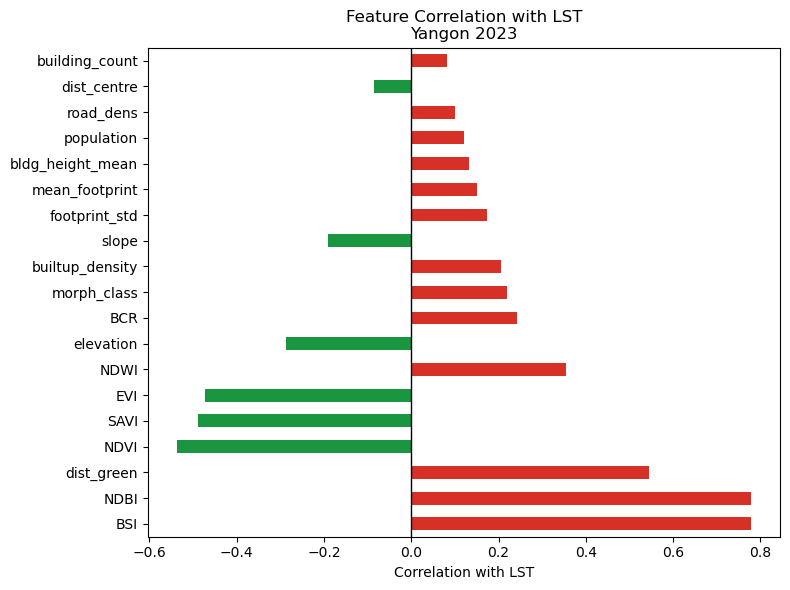

Chart saved!


In [4]:
# Correlation between each feature and LST
correlations = df_clean[FEATURES + [TARGET]].corr()[TARGET].drop(TARGET)
correlations_sorted = correlations.reindex(
    correlations.abs().sort_values(ascending=False).index
)

print("Feature correlations with LST:")
print("=" * 50)
for feat, corr in correlations_sorted.items():
    direction = "warming" if corr > 0 else "cooling"
    bar = "#" * int(abs(corr) * 30)
    print(f"  {feat:<15} {corr:+.3f}  {direction}  {bar}")

# Bar chart
fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#d73027' if c > 0 else '#1a9641'
          for c in correlations_sorted.values]
correlations_sorted.plot(kind='barh', ax=ax, color=colors)
ax.set_xlabel('Correlation with LST')
ax.set_title('Feature Correlation with LST\nYangon 2023')
ax.axvline(x=0, color='black', linewidth=1)
plt.tight_layout()

chart_dir = os.path.join(BASE, "outputs", "charts")
os.makedirs(chart_dir, exist_ok=True)
plt.savefig(os.path.join(chart_dir, "feature_correlations.png"),
            dpi=300, bbox_inches='tight')
plt.show()
print("Chart saved!")

In [5]:
# Remove UHI_mean — it is derived from LST
# Including it would cause data leakage
FEATURES = [f for f in FEATURES if f != 'UHI_mean']

X = df_clean[FEATURES].copy()
y = df_clean[TARGET].copy()

print(f"Updated features: {len(FEATURES)}")
print(f"X shape: {X.shape}")
print("UHI_mean removed to prevent data leakage")

Updated features: 19
X shape: (72481, 19)
UHI_mean removed to prevent data leakage


In [6]:
from sklearn.cluster import KMeans
import geopandas as gpd

print("Creating spatial cross-validation folds...")

# Load the grid to get true centroid coordinates
grid = gpd.read_file(os.path.join(BASE, "data", "vectors",
                                  "analysis_grid",
                                  "analysis_grid_with_townships.shp"))
grid = grid.to_crs(epsg=32647)
grid['cx'] = grid.geometry.centroid.x
grid['cy'] = grid.geometry.centroid.y

# Attach coordinates to the modelling table
df_clean = df_clean.merge(grid[['cell_id', 'cx', 'cy']],
                          on='cell_id', how='left')

# Cluster on real geographic position, not on distance variables
coords = df_clean[['cx', 'cy']].values
kmeans = KMeans(n_clusters=5, random_state=42, n_init=10)
df_clean['spatial_fold'] = kmeans.fit_predict(coords)

print("Spatial fold distribution:")
for fold in range(5):
    count = (df_clean['spatial_fold'] == fold).sum()
    print(f"  Fold {fold}: {count:,} cells")
print("Spatial folds created.")

Creating spatial cross-validation folds...
Spatial fold distribution:
  Fold 0: 14,578 cells
  Fold 1: 13,116 cells
  Fold 2: 17,207 cells
  Fold 3: 15,473 cells
  Fold 4: 12,107 cells
Spatial folds created.


In [7]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

print("Training models — please wait 5-15 minutes...")
print()

rf_results  = []
xgb_results = []

for fold in range(5):
    print(f"Fold {fold + 1}/5...")

    train_mask = df_clean['spatial_fold'] != fold
    test_mask  = df_clean['spatial_fold'] == fold

    X_train = X[train_mask]
    X_test  = X[test_mask]
    y_train = y[train_mask]
    y_test  = y[test_mask]

    # Random Forest
    rf = RandomForestRegressor(
        n_estimators=200,
        min_samples_split=5,
        random_state=42,
        n_jobs=-1
    )
    rf.fit(X_train, y_train)
    rf_pred = rf.predict(X_test)
    rf_results.append({
        'fold': fold,
        'R2':   r2_score(y_test, rf_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, rf_pred)),
        'MAE':  mean_absolute_error(y_test, rf_pred)
    })

    # XGBoost
    xgb_model = xgb.XGBRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=6,
        subsample=0.8,
        colsample_bytree=0.8,
        random_state=42,
        verbosity=0
    )
    xgb_model.fit(X_train, y_train)
    xgb_pred = xgb_model.predict(X_test)
    xgb_results.append({
        'fold': fold,
        'R2':   r2_score(y_test, xgb_pred),
        'RMSE': np.sqrt(mean_squared_error(y_test, xgb_pred)),
        'MAE':  mean_absolute_error(y_test, xgb_pred)
    })

    print(f"  RF:  R2={rf_results[-1]['R2']:.3f}  RMSE={rf_results[-1]['RMSE']:.3f}C")
    print(f"  XGB: R2={xgb_results[-1]['R2']:.3f}  RMSE={xgb_results[-1]['RMSE']:.3f}C")
    print()

rf_df  = pd.DataFrame(rf_results)
xgb_df = pd.DataFrame(xgb_results)

print("=" * 45)
print("FINAL RESULTS:")
print(f"Random Forest  R2={rf_df['R2'].mean():.3f}  RMSE={rf_df['RMSE'].mean():.3f}C")
print(f"XGBoost        R2={xgb_df['R2'].mean():.3f}  RMSE={xgb_df['RMSE'].mean():.3f}C")

Training models — please wait 5-15 minutes...

Fold 1/5...
  RF:  R2=0.642  RMSE=1.867C
  XGB: R2=0.643  RMSE=1.865C

Fold 2/5...
  RF:  R2=0.683  RMSE=2.666C
  XGB: R2=0.679  RMSE=2.684C

Fold 3/5...
  RF:  R2=0.546  RMSE=1.699C
  XGB: R2=0.537  RMSE=1.717C

Fold 4/5...
  RF:  R2=0.631  RMSE=2.115C
  XGB: R2=0.642  RMSE=2.083C

Fold 5/5...
  RF:  R2=0.709  RMSE=1.608C
  XGB: R2=0.730  RMSE=1.548C

FINAL RESULTS:
Random Forest  R2=0.642  RMSE=1.991C
XGBoost        R2=0.646  RMSE=1.980C


In [8]:
import joblib

print("Training final models on complete dataset...")

# Final Random Forest
rf_final = RandomForestRegressor(
    n_estimators=300,
    min_samples_split=5,
    random_state=42,
    n_jobs=-1
)
rf_final.fit(X, y)
print(f"RF final trained — Full R2={r2_score(y, rf_final.predict(X)):.3f}")

# Final XGBoost
xgb_final = xgb.XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    verbosity=0
)
xgb_final.fit(X, y)
print(f"XGB final trained — Full R2={r2_score(y, xgb_final.predict(X)):.3f}")

# Save models
models_dir = os.path.join(BASE, "outputs", "models")
os.makedirs(models_dir, exist_ok=True)
joblib.dump(rf_final,  os.path.join(models_dir, "rf_final.pkl"))
joblib.dump(xgb_final, os.path.join(models_dir, "xgb_final.pkl"))
print("Both models saved!")

# SHAP values — sample 5000 for speed
import shap
print("Calculating SHAP values (5 minutes)...")

X_sample = X.copy()
dmat = xgb.DMatrix(X_sample, feature_names=list(X_sample.columns))
contribs = xgb_final.get_booster().predict(dmat, pred_contribs=True)

# last column is the base value, not a feature
shap_values = contribs[:, :-1]
expected_value = float(contribs[0, -1])

print(f"SHAP matrix shape: {shap_values.shape}")
print(f"Base value: {expected_value:.3f} degrees C")

print("SHAP values ready!")

Training final models on complete dataset...
RF final trained — Full R2=0.966
XGB final trained — Full R2=0.836
Both models saved!
Calculating SHAP values (5 minutes)...
SHAP matrix shape: (72481, 19)
Base value: 43.082 degrees C
SHAP values ready!


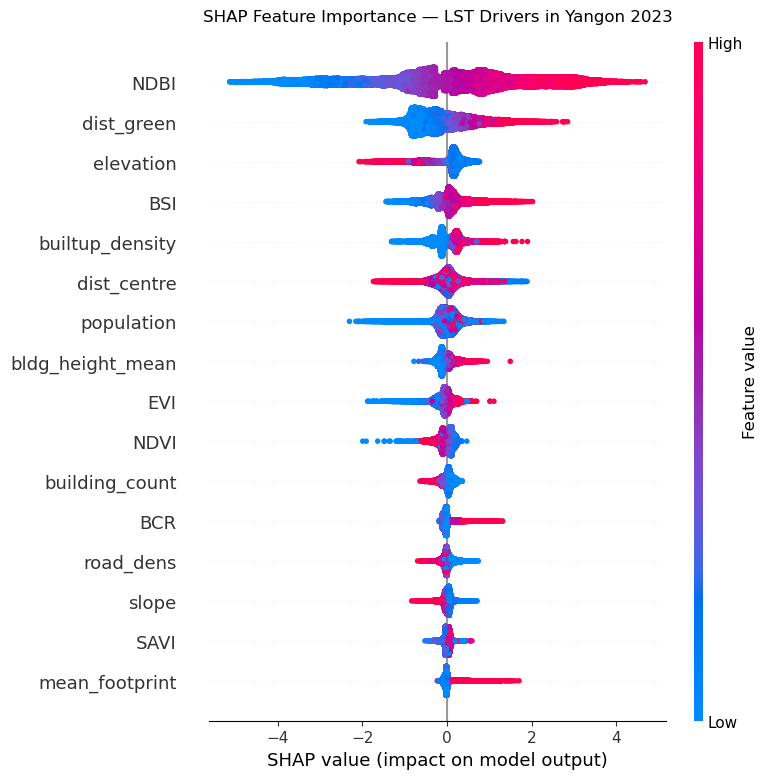

SHAP summary plot saved!


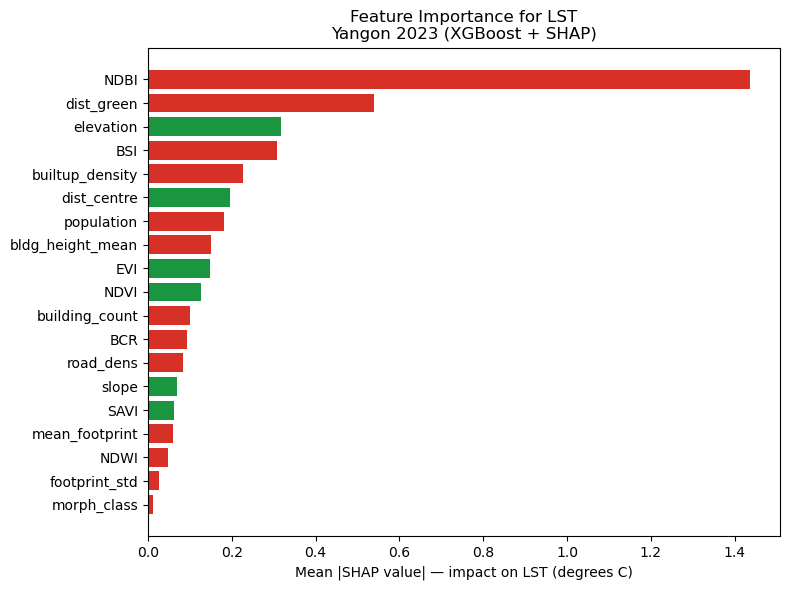

SHAP bar chart saved!

Top 5 most important features:
  1. NDBI: 1.4361C mean impact
  2. dist_green: 0.5397C mean impact
  3. elevation: 0.3185C mean impact
  4. BSI: 0.3089C mean impact
  5. builtup_density: 0.2275C mean impact


In [9]:
# SHAP Summary Plot — KEY THESIS FIGURE
plt.figure(figsize=(10, 7))
shap.summary_plot(
    shap_values,
    X_sample,
    feature_names=FEATURES,
    plot_type="dot",
    show=False,
    max_display=16
)
plt.title("SHAP Feature Importance — LST Drivers in Yangon 2023",
          fontsize=12, pad=15)
plt.tight_layout()
chart_dir = os.path.join(BASE, "outputs", "charts")
plt.savefig(os.path.join(chart_dir, "SHAP_summary_plot.png"),
            dpi=300, bbox_inches='tight')
plt.show()
print("SHAP summary plot saved!")

# Mean SHAP importance bar chart
mean_shap = np.abs(shap_values).mean(axis=0)
shap_df = pd.DataFrame({
    'feature': FEATURES,
    'importance': mean_shap
}).sort_values('importance', ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
colors = ['#d73027' if v > 0 else '#1a9641'
          for v in [df_clean[f].corr(df_clean['LST']) for f in shap_df['feature']]]
ax.barh(shap_df['feature'], shap_df['importance'], color=colors)
ax.set_xlabel('Mean |SHAP value| — impact on LST (degrees C)')
ax.set_title('Feature Importance for LST\nYangon 2023 (XGBoost + SHAP)')
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "SHAP_bar_importance.png"),
            dpi=300, bbox_inches='tight')
plt.show()
print("SHAP bar chart saved!")

# Print top 5 features
print("\nTop 5 most important features:")
top5 = shap_df.nlargest(5, 'importance')
for i, (_, row) in enumerate(top5.iterrows(), 1):
    print(f"  {i}. {row['feature']}: {row['importance']:.4f}C mean impact")

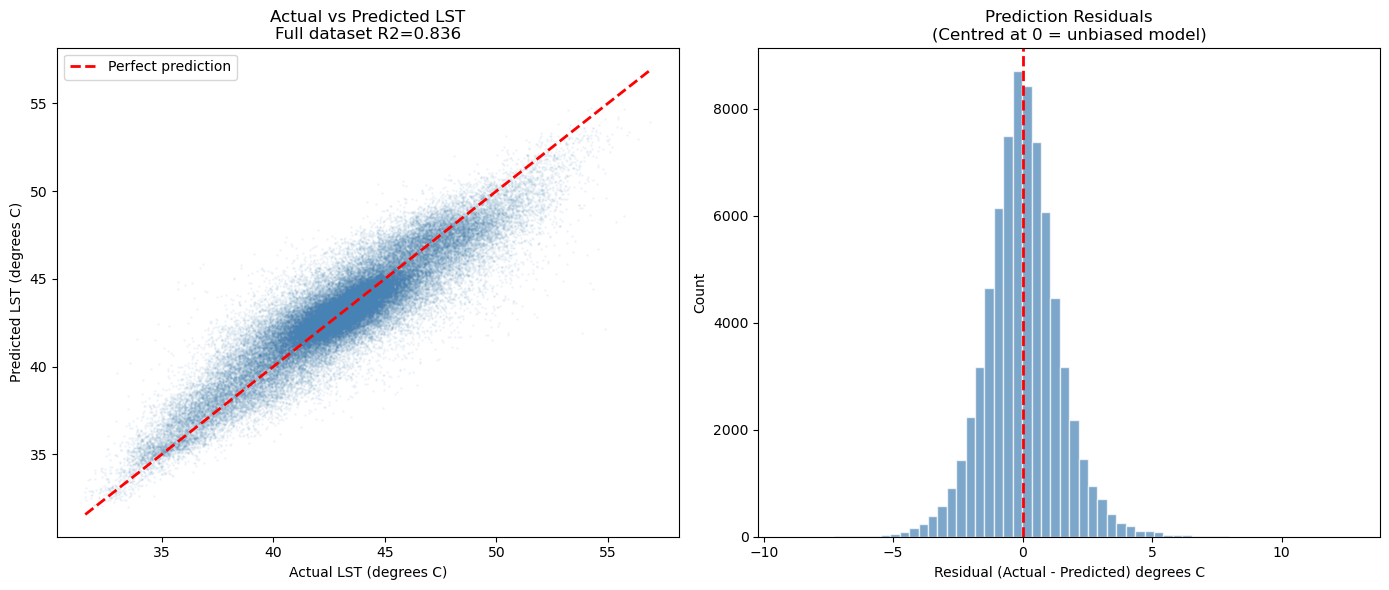

Prediction plot saved!
Results CSV saved: C:\Users\Khant Htoo Kyaw\Documents\Yangon_Thesis\data\tables\ML_results_with_predictions.csv

PHASE 4 COMPLETE!
  RF cross-val R2:  0.642
  XGB cross-val R2: 0.646
  Top feature: NDBI (1.436C SHAP impact)
  Models saved: outputs/models/
  Charts saved: outputs/charts/


In [11]:
# Add predictions to dataframe
df_clean['LST_predicted'] = xgb_final.predict(X)
df_clean['LST_residual']  = df_clean['LST'] - df_clean['LST_predicted']

# Actual vs Predicted scatter plot
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

ax1 = axes[0]
ax1.scatter(df_clean['LST'], df_clean['LST_predicted'],
            alpha=0.05, s=1, color='steelblue')
min_lst = df_clean['LST'].min()
max_lst = df_clean['LST'].max()
ax1.plot([min_lst, max_lst], [min_lst, max_lst],
         'r--', linewidth=2, label='Perfect prediction')
ax1.set_xlabel('Actual LST (degrees C)')
ax1.set_ylabel('Predicted LST (degrees C)')
ax1.set_title(f'Actual vs Predicted LST\nFull dataset R2={r2_score(df_clean["LST"], df_clean["LST_predicted"]):.3f}')
ax1.legend()

ax2 = axes[1]
ax2.hist(df_clean['LST_residual'], bins=60,
         color='steelblue', edgecolor='white', alpha=0.7)
ax2.axvline(x=0, color='red', linewidth=2, linestyle='--')
ax2.set_xlabel('Residual (Actual - Predicted) degrees C')
ax2.set_ylabel('Count')
ax2.set_title('Prediction Residuals\n(Centred at 0 = unbiased model)')

plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "actual_vs_predicted_LST.png"),
            dpi=300, bbox_inches='tight')
plt.show()

# Save results CSV
results_csv = os.path.join(BASE, "data", "tables",
                           "ML_results_with_predictions.csv")
save_cols = ['cell_id', 'cell_area', 'BCR', 'morph_cls',
             'NDVI', 'NDBI', 'BSI',
             'LST', 'LST_predicted', 'LST_residual',
             'spatial_fold'] + FEATURES
save_cols = [c for c in save_cols if c in df_clean.columns]
df_clean[save_cols].to_csv(results_csv, index=False)

print("Prediction plot saved!")
print(f"Results CSV saved: {results_csv}")
print()
print("PHASE 4 COMPLETE!")
print(f"  RF cross-val R2:  {rf_df['R2'].mean():.3f}")
print(f"  XGB cross-val R2: {xgb_df['R2'].mean():.3f}")
print(f"  Top feature: {shap_df.iloc[-1]['feature']} ({shap_df.iloc[-1]['importance']:.3f}C SHAP impact)")
print(f"  Models saved: outputs/models/")
print(f"  Charts saved: outputs/charts/")

VARIANCE INFLATION FACTORS

         feature    VIF
            SAVI 112.33
            NDVI  72.84
             BSI  60.23
             EVI  57.84
            NDWI  38.43
            NDBI  30.77
             BCR  10.37
     morph_class   8.10
bldg_height_mean   4.60
 builtup_density   4.19
      population   2.97
  building_count   2.62
   footprint_std   2.18
  mean_footprint   1.81
     dist_centre   1.75
       road_dens   1.71
      dist_green   1.44
       elevation   1.40
           slope   1.23

Partial dependence for: ['NDBI', 'dist_green', 'elevation']


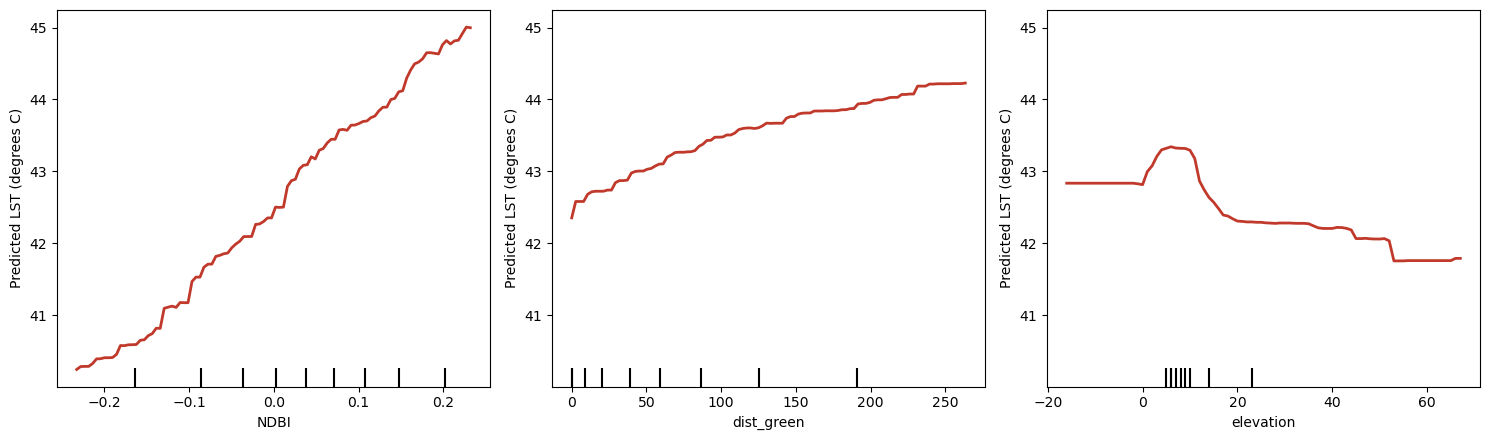


Saved: VIF_table.csv, partial_dependence_top3.png, SHAP_per_cell_top3.csv
Join SHAP_per_cell_top3.csv to the analysis grid in QGIS on cell_id to map each driver.


In [12]:
import numpy as np, pandas as pd, os
import matplotlib.pyplot as plt

chart_dir = os.path.join(BASE, "outputs", "charts")

# ── 1. VIF table ──────────────────────────────────────────────
Xv = X.astype(float).values
Xs = (Xv - Xv.mean(0)) / Xv.std(0)
vif = {}
for i, f in enumerate(FEATURES):
    yv = Xs[:, i]
    A = np.c_[np.delete(Xs, i, axis=1), np.ones(len(Xs))]
    b, *_ = np.linalg.lstsq(A, yv, rcond=None)
    r2 = 1 - ((yv - A @ b) ** 2).sum() / ((yv - yv.mean()) ** 2).sum()
    vif[f] = 1 / max(1e-12, 1 - r2)

vif_df = pd.DataFrame(sorted(vif.items(), key=lambda x: -x[1]),
                      columns=['feature', 'VIF'])
print("VARIANCE INFLATION FACTORS\n")
print(vif_df.to_string(index=False, float_format='%.2f'))
vif_df.to_csv(os.path.join(BASE, "data", "tables", "VIF_table.csv"), index=False)

# ── 2. Partial dependence for top 3 ───────────────────────────
from sklearn.inspection import PartialDependenceDisplay
top3 = shap_df.nlargest(3, 'importance')['feature'].tolist()
print(f"\nPartial dependence for: {top3}")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
PartialDependenceDisplay.from_estimator(
    xgb_final, X, top3, ax=ax, line_kw={'color': '#c0392b', 'linewidth': 2})
for a in ax:
    a.set_ylabel('Predicted LST (degrees C)')
plt.tight_layout()
plt.savefig(os.path.join(chart_dir, "partial_dependence_top3.png"),
            dpi=300, bbox_inches='tight')
plt.show()

# ── 3. Per-cell SHAP values for mapping in QGIS ───────────────
shap_out = pd.DataFrame(shap_values, columns=FEATURES)
shap_out['cell_id'] = df_clean['cell_id'].values
keep = ['cell_id'] + top3
shap_out[keep].rename(
    columns={f: f'shap_{f}' for f in top3}
).to_csv(os.path.join(BASE, "data", "tables", "SHAP_per_cell_top3.csv"),
         index=False)

print(f"\nSaved: VIF_table.csv, partial_dependence_top3.png, SHAP_per_cell_top3.csv")
print("Join SHAP_per_cell_top3.csv to the analysis grid in QGIS on cell_id to map each driver.")

In [13]:
print(shap_df.sort_values('importance', ascending=False).to_string(index=False))

         feature  importance
            NDBI    1.436100
      dist_green    0.539697
       elevation    0.318515
             BSI    0.308909
 builtup_density    0.227504
     dist_centre    0.195109
      population    0.180855
bldg_height_mean    0.149818
             EVI    0.147969
            NDVI    0.125886
  building_count    0.099435
             BCR    0.092431
       road_dens    0.084129
           slope    0.069174
            SAVI    0.063230
  mean_footprint    0.059611
            NDWI    0.048866
   footprint_std    0.025416
     morph_class    0.012284
